In [4]:
import os
print(os.getcwd())

import pandas as pd
import numpy as np

# Subimos un nivel con '../' para salir de la carpeta notebooks y encontrar data
df = pd.read_csv('../data/processed/ofertas_tech_limpio.csv')

# Mostramos las primeras 5 filas
df.head()


c:\Users\maraf\OneDrive\Escritorio\data\Consulting-Challenge-dev\notebooks


,title,rol,company_name,country,city,work_model,employment_type,education_level,date_posted,seniority,tiene_skills,skills,cantidad_skills,salario_anual_usd
0,Full Stack Developer,Full Stack Developer,Rockwool International,Malaysia,Subang Jaya,On-site,Full-time,NaN,NaN,Sin datos,True,.net|c#|react|typescript|azure|ci/cd|docker|agile,8,NaN
1,Senior Full Stack Engineer (Python / React),Full Stack Developer,Skinandme,United Kingdom,London,Hybrid,Full-time,NaN,NaN,Senior,True,full-stack development|python/flask|react/type...,8,NaN
2,Senior Full Stack Engineer (Node / Typescript ...,Full Stack Developer,Skinandme,United Kingdom,London,Hybrid,Full-time,NaN,NaN,Senior,True,node.js|typescript|react|mysql|aws|docker|api ...,8,NaN
3,Full Stack Engineer (Python / React),Full Stack Developer,Skinandme,United Kingdom,London,Hybrid,Full-time,NaN,NaN,Semi Senior,False,NaN,0,NaN
4,Business Intelligence Analyst I,Data Analyst,Teleperformance,India,Malad,On-site,Full-time,NaN,NaN,Junior,True,data analysis|bi reporting|trend analysis|stak...,4,NaN


In [5]:
#Estadísticas descriptiva

# Resumen estadístico de las variables numéricas
print("--- Estadísticas Descriptivas ---")
display(df.describe())


--- Estadísticas Descriptivas ---


,cantidad_skills,salario_anual_usd
count,1075.000000,340.000000
mean,7.188837,142539.618853
std,2.714995,49379.123896
min,0.000000,31200.000000
25%,8.000000,113700.000000
50%,8.000000,131650.000000
75%,8.000000,171734.750000
max,27.000000,313500.000000


#El primer análisis arroja los siguientes resultados: 
cantidad total de 1.075 ofertas que contienen datos 
Obtenemos un percentil de 25%, una mediana de 50% y el percentil 75% esta en 8. O sea que la mayoría de ofertas laborales requieren de que el solicitante tenga exactamente 8 habilidades requeridas para el puesto. El mínimo de habilidades es 0 y el máximo son 27 habilidades por oferta laboral. 

Por otro lado y en cuanto a los salarios: 
De las 1.075 ofertas que aparecen solo 340 tienen registro del salario. Hay muchas ofertas que el anunciante no publica el salario o no hay regitro. (valores nulos).
En el caso de las ofertas que si cuentan con datos de salario el promedio que pagan es de usd 142,539 anuales y la mitad de esos salarios ganan mas de usd 131,650 anuales. 


In [6]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1075 entries, 0 to 1074
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   title              1075 non-null   str    
 1   rol                1075 non-null   str    
 2   company_name       1075 non-null   str    
 3   country            1075 non-null   str    
 4   city               1075 non-null   str    
 5   work_model         1075 non-null   str    
 6   employment_type    1075 non-null   str    
 7   education_level    107 non-null    str    
 8   date_posted        218 non-null    str    
 9   seniority          1075 non-null   str    
 10  tiene_skills       1075 non-null   bool   
 11  skills             961 non-null    str    
 12  cantidad_skills    1075 non-null   int64  
 13  salario_anual_usd  340 non-null    float64
dtypes: bool(1), float64(1), int64(1), str(11)
memory usage: 110.4 KB


Matplotlib is building the font cache; this may take a moment.


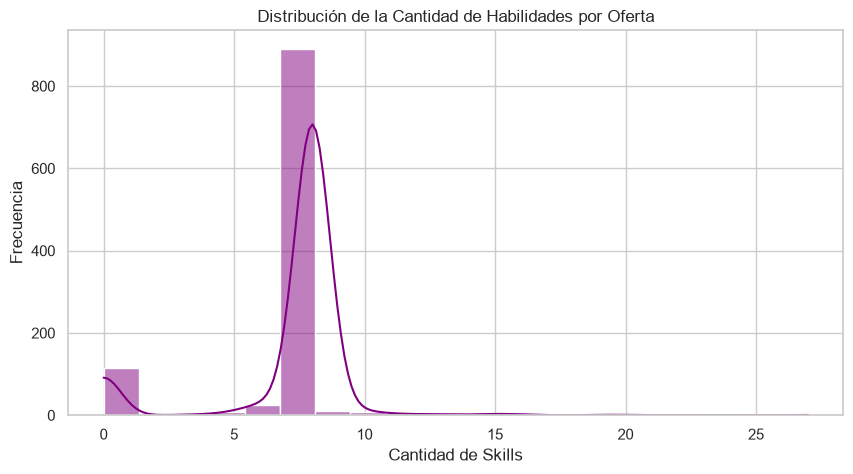

In [7]:
# Distribuciones 
import matplotlib.pyplot as plt
import seaborn as sns

# Configuracion  del estilo visual
sns.set_theme(style="whitegrid")

# Gráfico de distribución de la cantidad de habilidades que hay
plt.figure(figsize=(10, 5))
sns.histplot(df['cantidad_skills'].dropna(), bins=20, kde=True, color='purple')
plt.title('Distribución de la Cantidad de Habilidades por Oferta')
plt.xlabel('Cantidad de Skills')
plt.ylabel('Frecuencia')
plt.show()


El gráfico respalda lo anotado anteriormente: La barra se acerca al 8 (gran concentracion/ moda clara) casi 900 ofertas laborales piden esa cantidad de habilidades (8). El mínimo de habilidades la barra esta cerca del 0 que son las ofertas que no se especificaron o que no requieren que se tenga habilidaes de forma estructurada. 
Por último cola hacia la derecha nos refleja que una pequeñna dispersión que se alarga hasta llegar a las 27 habilidades que son los casos expecionales. 

C:\Users\maraf\AppData\Local\Temp\ipykernel_1444\1659165267.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='seniority', y='cantidad_skills', data=df, palette='Set2')


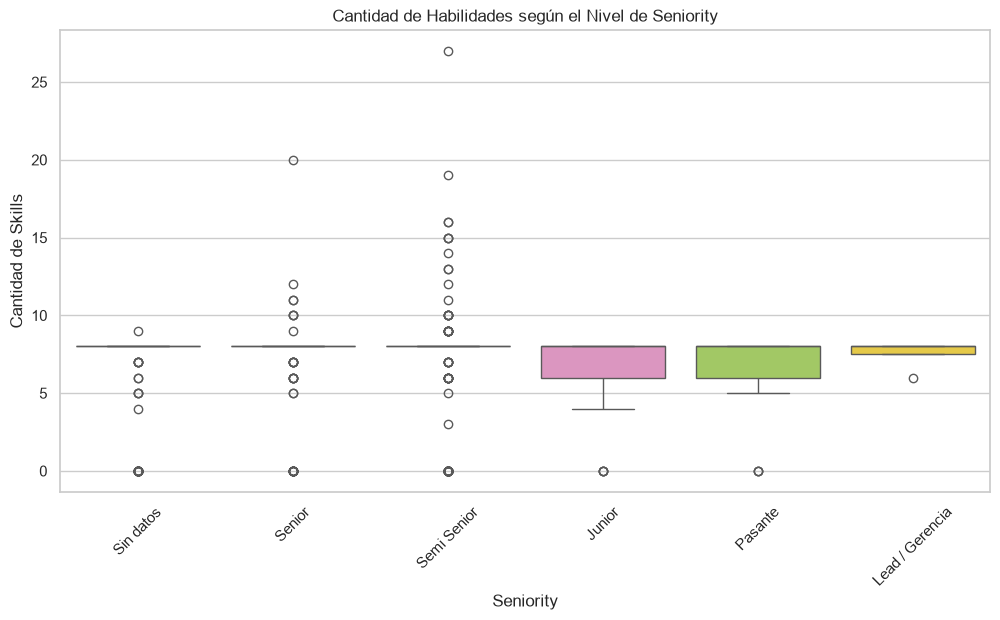

In [8]:
# Relación entre Seniority y la cantidad de skills requeridas
plt.figure(figsize=(12, 6))
sns.boxplot(x='seniority', y='cantidad_skills', data=df, palette='Set2')
plt.title('Cantidad de Habilidades según el Nivel de Seniority')
plt.xlabel('Seniority')
plt.ylabel('Cantidad de Skills')
plt.xticks(rotation=45)
plt.show()

El gráfico actual refeleja lo que venimos viendo:
 Para los puestos de senior, semi senior y los que no se especifican el nivel todos piden lo mismo. Tener 8 habilidades por eso la gráfica se ve plana justo en el n°. Basicamente NO importa el título, piden lo mismo. 
 Las escepciones: en los puestos de senior y semi senior hay ofertas que estan raras, son los puntitos de arriba. Eso es porque salen de lo normal porque piden una lista exagerada de tecnologías (entre 20 y 27)
 Los puestos de Junior y pasante que son los que recien inician, los requisitos varian un poco más y por lo general se pide que tengan entre 6 y 8 habilidades. Tambien hay algun caso, pocos pero hay que no piden ninguna habilidad y se marca en 0.

Límite inferior: 8.0
Límite superior: 8.0
Total de registros considerados outliers en 'cantidad_skills': 203


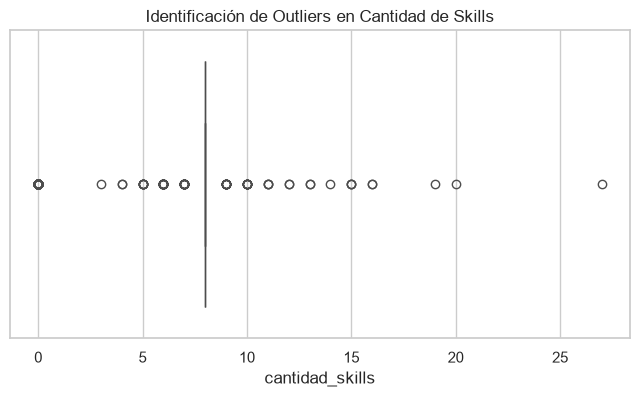

In [9]:
# Detección de outliers usando el método IQR para 'cantidad_skills'
Q1 = df['cantidad_skills'].quantile(0.25)
Q3 = df['cantidad_skills'].quantile(0.75)
IQR = Q3 - Q1

# Definimos los límites inferior y superior
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtramos los outliers
outliers = df[(df['cantidad_skills'] < limite_inferior) | (df['cantidad_skills'] > limite_superior)]

print(f"Límite inferior: {limite_inferior}")
print(f"Límite superior: {limite_superior}")
print(f"Total de registros considerados outliers en 'cantidad_skills': {len(outliers)}")

# Visualización rápida en boxplot para detectarlos
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['cantidad_skills'], color='orange')
plt.title('Identificación de Outliers en Cantidad de Skills')
plt.show()

Detección de outliers (valores atípicos)
Al aplicar el método IQR sobre la variable cantidad_skills, según el gráfico los límites inferior y superior se fijaron en el valor 8 debido a la masiva consentración de las ofertas en ese número. Se identificaron 203 registros considerados outliers que sería el 18.8% del total. Esto nos confirma que numéricamente aunque el mercado sigue una regla estandar de pedir 8 tecnologías por puest existe una dispersión marcada de pfertas laborales que salen de esa regla, ya sea exigiendo menos 0 o exigiendo más como 27 habilidades. 

--- Top 10 Tecnologías más demandadas ---
python                438
sql                   301
ci/cd                 295
kubernetes            202
aws                   181
java                  143
docker                134
react                 127
terraform             127
data visualization     94
Name: count, dtype: int64


C:\Users\maraf\AppData\Local\Temp\ipykernel_1444\3516943794.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_skills.values, y=top_skills.index, palette='viridis')


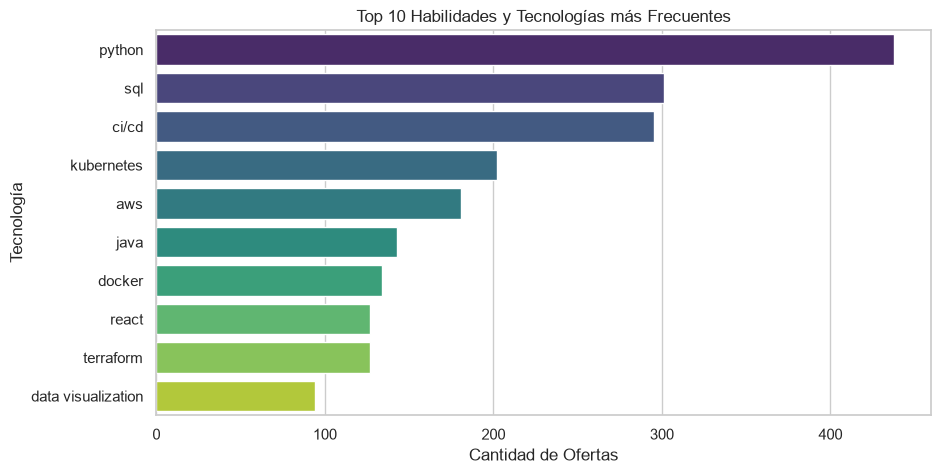

In [10]:
# Contar las tecnologías más frecuentes separando los valores por el carácter '|'
todas_las_skills = df['skills'].dropna().str.cat(sep='|').split('|')
top_skills = pd.Series(todas_las_skills).value_counts().head(10)

print("--- Top 10 Tecnologías más demandadas ---")
print(top_skills)

# Gráfico de barras horizontal para el Top 10
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.barplot(x=top_skills.values, y=top_skills.index, palette='viridis')
plt.title('Top 10 Habilidades y Tecnologías más Frecuentes')
plt.xlabel('Cantidad de Ofertas')
plt.ylabel('Tecnología')
plt.show()

Según el gráfico obtenido:
Python lidera con una mención de 438 veces. Consolidándose como lenguaje o requisito que más se pide en las ofertas laborales. 
Luego le sigue SQL con 301 y CI/CD con 295 menciones. Se muestra un fuerte peso de las bases de datos y las prácticas de automatización/ despliegue continuo. 
En cuanto a las herramientas de infrastructura, contenedores y nube como por ejemplo Kubernetes mencionado 202, AWS con 181 y docker con 134 tienen una presencia sólida asi como las tecnologías de desarrollo web como react (127), lenguajes como JAVA con 143 e infrastructuras como código de terraform con 127 menciones y por último visualización de datos con 94 menciones.   

In [11]:
# Analizar la cantidad de ofertas y el promedio de skills según el rol tecnológico
resumen_roles = df.groupby('rol')['cantidad_skills'].agg(['count', 'mean', 'median']).reset_index()
resumen_roles.columns = ['Rol', 'Total Ofertas', 'Promedio Skills', 'Mediana Skills']

# Ordenar de mayor a menor según la cantidad total de ofertas
resumen_roles = resumen_roles.sort_values(by='Total Ofertas', ascending=False)

print("--- Demanda y Exigencia según el Rol ---")
display(resumen_roles)

--- Demanda y Exigencia según el Rol ---


,Rol,Total Ofertas,Promedio Skills,Mediana Skills
0,Cloud Engineer,310,7.248387,8.0
3,Full Stack Developer,255,7.286275,8.0
1,Data Analyst,181,6.392265,8.0
4,QA Engineer,173,7.664740,8.0
2,Data Scientist,156,7.307692,8.0


Volumen de ofertas por rol y exigencia técnica

La tabla nos muestra que los puestos que mas concentran oportunidades laborales en el mercado son los puestos de ifrastructura e ingenieria en la nube: como Cloud engineer con 310 ofertas y de desarrollo como Full strack developer con 255 ofertas. En cuanto a la exigencia técnica, aunque la norma general de solicitar 8 habilidades predomina en todos los perfiles, los ingenieros de calidad (QA engineer) y científicos de datos muestran variaciones con un promedio ligeramente superior de herramientas requeridas por oferta, reflejando la polivalencia técnica que se les demanda. 

In [20]:
# Analizar la distribución por Seniority y por Nivel Educativo
print("--- Distribución por Seniority ---")
conteo_seniority = df['seniority'].value_counts()
display(conteo_seniority)

print("\n--- Distribución por Nivel Educativo ---")
conteo_educacion = df['education_level'].value_counts(dropna=False)
display(conteo_educacion)

--- Distribución por Seniority ---


seniority
Semi Senior        557
Senior             269
Sin datos          205
Junior              22
Pasante             18
Lead / Gerencia      4
Name: count, dtype: int64


--- Distribución por Nivel Educativo ---


education_level
NaN                                                                                                                                             968
Bachelor's                                                                                                                                       18
Bachelor’s degree in Computer Science, Engineering, or related field                                                                              6
Bachelor’s degree                                                                                                                                 5
Bachelor's degree                                                                                                                                 3
                                                                                                                                               ... 
Bachelor's or Master's in Computer Science/IT                                                   

Perfil profesional:
Experiencia y seniority las empresas buscan principalmente perfiles con experiencia consolidados, concentrandose la demanda en las categorias semi sr con 557 ofertas y sr con 269 ofertas. Mientras que las oportunidades de nivel inicial jr y pasantes tienen un presencia marginal en este conjunto de datos analizados. 

Formación: se observa una ausencia masiva de datos en el nivel educativo con 968 valores nulos, lo que indica que los reclutadores ponen el foco en listar herramientas tecnológicas específicas en lugar de exigir títulos académicos formales específicos. 

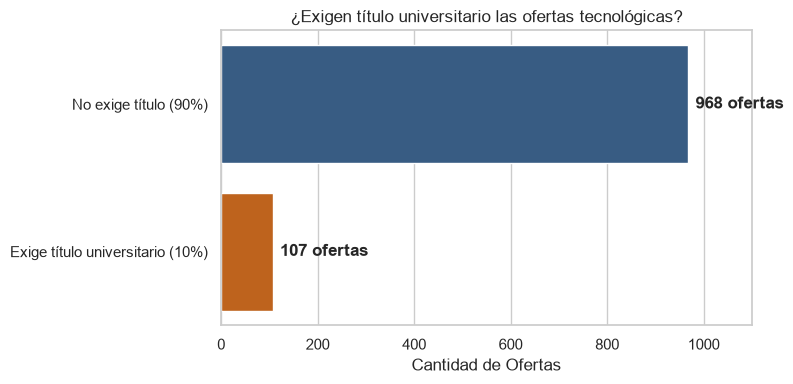

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Agrupar en dos categorías simples: Pide título vs. No pide título
requisito_titulo = df['education_level'].notna().map({
    False: 'No exige título (90%)',
    True: 'Exige título universitario (10%)'
})

conteo_edu = requisito_titulo.value_counts()

# 2. Crear el gráfico sin advertencias de Seaborn
plt.figure(figsize=(8, 4))
sns.barplot(
    x=conteo_edu.values, 
    y=conteo_edu.index, 
    hue=conteo_edu.index, 
    palette=['#2b5c8f', '#d95f02'], 
    legend=False
)

plt.title('¿Exigen título universitario las ofertas tecnológicas?')
plt.xlabel('Cantidad de Ofertas')
plt.ylabel('')
plt.xlim(0, 1100)

# 3. Agregar los números exactos al final de cada barra
for index, value in enumerate(conteo_edu.values):
    plt.text(value + 15, index, f'{value} ofertas', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [19]:
import pandas as pd

# Clasificar las 71 variantes de texto en grupos claros
def agrupar_titulo(texto):
    if pd.isna(texto):
        return 'Sin requisito especificado (NaN)'
    texto_lower = str(texto).lower()
    if 'phd' in texto_lower or 'doctorate' in texto_lower:
        return 'Doctorado (PhD)'
    elif 'master' in texto_lower and 'bachelor' in texto_lower:
        return 'Licenciatura / Ingeniería o Maestría'
    elif 'master' in texto_lower:
        return 'Maestría (Master)'
    else:
        return 'Licenciatura / Ingeniería (Bachelor)'

# Crear tabla resumen
tabla_educacion = df['education_level'].apply(agrupar_titulo).value_counts().reset_index()
tabla_educacion.columns = ['Nivel Educativo Exigido', 'Cantidad de Ofertas']
tabla_educacion['Porcentaje (%)'] = (tabla_educacion['Cantidad de Ofertas'] / len(df) * 100).round(1)

display(tabla_educacion)

,Nivel Educativo Exigido,Cantidad de Ofertas,Porcentaje (%)
0,Sin requisito especificado (NaN),968,90.0
1,Licenciatura / Ingeniería (Bachelor),85,7.9
2,Licenciatura / Ingeniería o Maestría,11,1.0
3,Maestría (Master),9,0.8
4,Doctorado (PhD),2,0.2


In [13]:
# Ver todas las columnas del dataset y una muestra de las primeras filas
print("Columnas disponibles:", df.columns.tolist())
display(df.head(3))

Columnas disponibles: ['title', 'rol', 'company_name', 'country', 'city', 'work_model', 'employment_type', 'education_level', 'date_posted', 'seniority', 'tiene_skills', 'skills', 'cantidad_skills', 'salario_anual_usd']


,title,rol,company_name,country,city,work_model,employment_type,education_level,date_posted,seniority,tiene_skills,skills,cantidad_skills,salario_anual_usd
0,Full Stack Developer,Full Stack Developer,Rockwool International,Malaysia,Subang Jaya,On-site,Full-time,NaN,NaN,Sin datos,True,.net|c#|react|typescript|azure|ci/cd|docker|agile,8,NaN
1,Senior Full Stack Engineer (Python / React),Full Stack Developer,Skinandme,United Kingdom,London,Hybrid,Full-time,NaN,NaN,Senior,True,full-stack development|python/flask|react/type...,8,NaN
2,Senior Full Stack Engineer (Node / Typescript ...,Full Stack Developer,Skinandme,United Kingdom,London,Hybrid,Full-time,NaN,NaN,Senior,True,node.js|typescript|react|mysql|aws|docker|api ...,8,NaN



Las tendencias del mercado y las modalidades de contratación: El análisis de las ofertas evidencia una clara consolidación de esquemas de trabajo flexibles (híbrido y remoto), alineados con las demandas de los profesionales tecnológicos modernos. Asimismo, la presencia de múltiples países y ciudades indica un mercado globalizado donde las exigencias técnicas se estandarizan (con un promedio constante de 8 tecnologías por rol) sin importar la ubicación geográfica de la vacante.

C:\Users\maraf\AppData\Local\Temp\ipykernel_1444\2566744850.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=conteo_seniority.values, y=conteo_seniority.index, palette='mako')


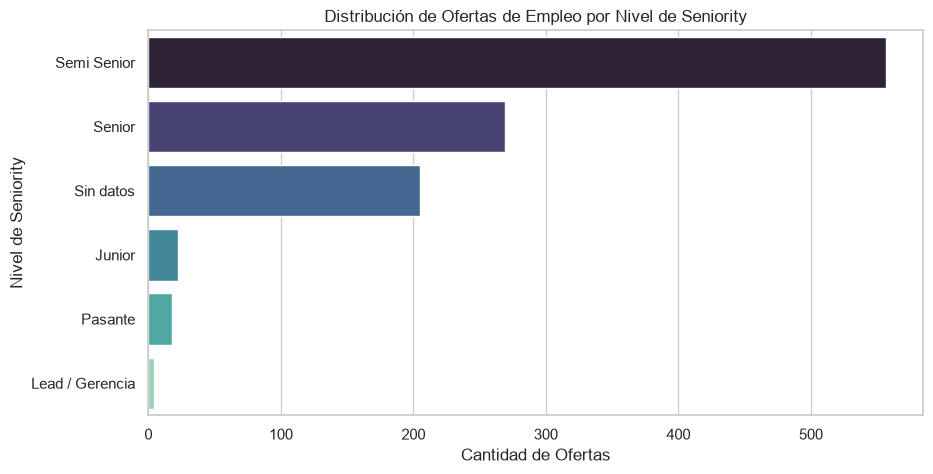

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Contar la distribución por seniority
conteo_seniority = df['seniority'].value_counts()

# Crear el gráfico
plt.figure(figsize=(10, 5))
sns.barplot(x=conteo_seniority.values, y=conteo_seniority.index, palette='mako')
plt.title('Distribución de Ofertas de Empleo por Nivel de Seniority')
plt.xlabel('Cantidad de Ofertas')
plt.ylabel('Nivel de Seniority')
plt.show()

PASO A PASO DE COMO REPLICAR LA EXTRACCIÓN DE LOS DATOS:

Tenemos que importar las librerías necesarias (pandas, numpy, matplotlib, seaborn,etc) y además cargar el archivo CVS en un Dataframe de pandas ajustando la ruta correcta según la unbicación del cuaderno 

Luego: 

1- ESTADÍSTICA DESCRIPTIVA E INFORMACIÓN GENERAL
Se debe ejecutar un resumen estadístico de las variables numéricas para identificar mérticas clave como la media, mediana y percentiles. 

df.describe()

Luego se revisa la estructura general de nuestro Dataframe, los tipos de datos y la cantidad de valores nulos o faltantes en cada columna.

df.info() 

2- ANÁLISIS DE DESTRIBUCIÓN/ VISUALIZACIÓN 
Se debe graficar un histograma con curva de densidad (kde) de la variable numérica principal o sea (cantidad_skills) para poder detectar dónde se concentra visualmente la mayor cantidad de datos: 

plt.figure(figsize=(10, 5))
sns.histplot(df['cantidad_skills'].dropna(), bins=20, kde=True, color='purple')
plt.title('Distribución de la Cantidad de Habilidades por Oferta')
plt.show()

3- RELACIONES ENTRE LAS VARIABLES:
sE debe cruzar un variable categórica como por ejemplo seniority con una variable numérica ej:cantidad_skills mediante un diagrama de caja (boxplot) para analizar asi los requisitos que cambian según el nivel de experiencia. 

plt.figure(figsize=(12, 6))
sns.boxplot(x='seniority', y='cantidad_skills', data=df, palette='Set2')
plt.title('Cantidad de Habilidades según el Nivel de Seniority')
plt.show()

4- DETECTAR MATEMATICAMENTE Y VISUALIZACIÓN DE OUTLIERS 
Se debe calcular el rango intercuartílico o IQR para poder establecer los límites estadísticos inferior y superior.

Q1 = df['cantidad_skills'].quantile(0.25)
Q3 = df['cantidad_skills'].quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

Se filtra y se cuenta los registros que superan dichos límites para poder obtener asi el numero total de valores atípicos 

outliers = df[(df['cantidad_skills'] < limite_inferior) | (df['cantidad_skills'] > limite_superior)]
print(f"Total de outliers: {len(outliers)}")

Se comprueba el resultado visualmente con un boxplot individual

plt.figure(figsize=(8, 4))
sns.boxplot(x=df['cantidad_skills'], color='orange')
plt.show()

Y listo se expone la conclusión final. 